# Events

Events are time points marked during a recording, usually triggers that
the experiment software sends to the eye tracker (e.g., "stimulus on",
"response"). Each event has an onset time and a label. This tutorial
shows how to look at events, select the ones you need and change them,
using the `Events` class.

In [1]:
import pypillometry as pp
from pypillometry import u
import numpy as np
import matplotlib.pyplot as plt

pp.logging_set_level("WARNING")

d = pp.get_example_data("rlmw_002_short")

## Getting the events

`get_events()` returns the events of a dataset as an `Events` object. In a
notebook, it is shown as a table:

In [2]:
events = d.get_events()
events

,Onset (ms),Label
0,5177.0,F_1
1,5677.0,S_1_1_5
2,6773.0,C_1_5_2
3,7010.0,R_1_15
4,8776.0,F_2
5,9575.0,S_2_6_2
6,10581.0,C_2_6_1
7,10808.0,R_2_20
8,12374.0,F_3
9,12574.0,S_3_2_1


The onsets are in ms by default. Use `units=` to get them in other
units, or convert an existing object with `to_units()`:

In [3]:
d.get_events(units="sec")[:4]

,Onset (sec),Label
0,5.177,F_1
1,5.677,S_1_1_5
2,6.773,C_1_5_2
3,7.010,R_1_15


In [4]:
events.to_units("min").onsets[:4]

array([0.08628333, 0.09461667, 0.11288333, 0.11683333])

The onsets and labels are stored as numpy arrays. An `Events` object has a
length and can be iterated over and indexed like a list. Indexing returns
a new `Events` object:

In [5]:
print(len(events))
for onset, label in events[:3]:
    print(f"{label:10s} at {onset:.0f} ms")

40
F_1        at 5177 ms
S_1_1_5    at 5677 ms
C_1_5_2    at 6773 ms


In [6]:
events.onsets[:5], events.labels[:5]

(array([5177., 5677., 6773., 7010., 8776.]),
 array(['F_1', 'S_1_1_5', 'C_1_5_2', 'R_1_15', 'F_2'], dtype='<U8'))

## Selecting events

`filter()` returns the events that match a criterion. There are three
kinds of criteria.

**A string** selects all labels that contain it:

In [7]:
events.filter("S_")

,Onset (ms),Label
0,5677.0,S_1_1_5
1,9575.0,S_2_6_2
2,12574.0,S_3_2_1
3,16473.0,S_4_4_1
4,20388.0,S_5_3_5
5,23987.0,S_6_4_5
6,27002.0,S_7_3_1
7,30601.0,S_8_6_5
8,34799.0,S_9_4_6
9,38415.0,S_10_2_5


**A function** is called with each label and selects the events for which
it returns `True`. In this dataset, the labels of the `R` events end with
a number; here we select those where it is larger than 18:

In [8]:
def high_number(label):
    parts = label.split("_")
    return parts[0] == "R" and int(parts[-1]) > 18

events.filter(high_number)

,Onset (ms),Label
0,10808.0,R_2_20
1,25153.0,R_6_20
2,35932.0,R_9_19


**A tuple** `(start, end)` selects events by their onset, in the units of
the `Events` object (here, ms):

In [9]:
events.filter((10_000, 20_000))

,Onset (ms),Label
0,10581.0,C_2_6_1
1,10808.0,R_2_20
2,12374.0,F_3
3,12574.0,S_3_2_1
4,13733.0,C_3_2_1
5,13957.0,R_3_18
6,15973.0,F_4
7,16473.0,S_4_4_1
8,17589.0,C_4_1_2
9,17822.0,R_4_11


Since `filter()` returns a new `Events` object, filters can be chained,
e.g., the `S` events in the first 20 seconds:

In [10]:
events.filter("S_").filter((0, 20_000))

,Onset (ms),Label
0,5677.0,S_1_1_5
1,9575.0,S_2_6_2
2,12574.0,S_3_2_1
3,16473.0,S_4_4_1


`test_selector()` shows which events of a dataset a selector picks out, which
is useful while writing a selection function:

In [11]:
from pypillometry.convenience import test_selector
test_selector(d, high_number)

array(['R_2_20', 'R_6_20', 'R_9_19'], dtype=object)

## Plotting events

`plot()` shows when the events happened. Each event is a point; the
labels of some of them are shown (use `show_labels="all"` for all):

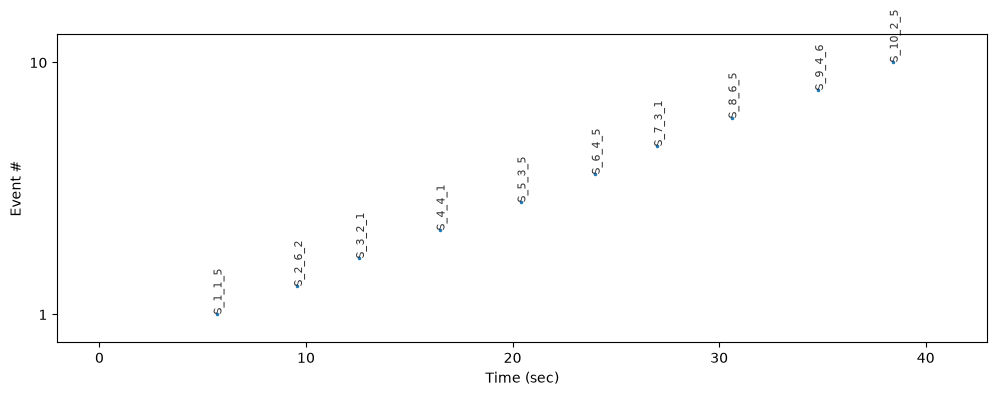

In [12]:
plt.figure(figsize=(12, 4))
events.filter("S_").plot(units="sec", show_labels="all")

Events are also shown in most plots of the data, e.g., in
`d.plot.pupil_plot()`.

## Using events for intervals

Analyses usually look at the data around events. `get_intervals()` takes
the same kinds of selectors as `filter()` (string or function), and also
an `Events` object. This makes it easy to use any selection of events,
e.g., only the first five stimuli:

In [13]:
first_stimuli = events.filter("S_")[:5]
d.get_intervals(first_stimuli, (-200, 800) * u.ms)

Intervals 'events_5' | 5 intervals (total duration: 5000.00 ms), 1000.00 ms +/- 0.00 ms, [1000.00 ms, 1000.00 ms] | fs=500.0Hz

See the [Intervals tutorial](intervals.ipynb) for more on intervals.

## Creating and changing events

`Events` objects can also be created directly. Onsets with units are
converted, and the object keeps the units:

In [14]:
my_events = pp.Events([1, 2.5, 4] * u.sec, ["start", "probe", "end"])
my_events

,Onset (sec),Label
0,1.0,start
1,2.5,probe
2,4.0,end


`set_events()` replaces the events of a dataset. For example, we can
shorten the labels to just the event type (the first letter). The onsets
stay the same:

In [15]:
short_labels = [label.split("_")[0] for label in events.labels]
d.set_events(pp.Events(events.onsets, short_labels))
d.get_events()[:6]

,Onset (ms),Label
0,5177.0,F
1,5677.0,S
2,6773.0,C
3,7010.0,R
4,8776.0,F
5,9575.0,S


Like other methods, `set_events()` changes the object in place unless
`inplace=False` is given.

As another example, we add the onset of each blink as an event. Blinks
are stored as `Intervals` (see the [blinks tutorial](blinks.ipynb)); we
take their start times in ms, combine them with the existing events and
sort everything by time:

In [16]:
d.pupil_blinks_detect(apply_mask=True)
blinks = d.get_blinks("left", "pupil", units="ms")
blink_onsets = [start for start, end in blinks]

events = d.get_events()
onsets = np.concatenate([events.onsets, blink_onsets])
labels = np.concatenate([events.labels, ["blink"] * len(blink_onsets)])
order = np.argsort(onsets)
d.set_events(pp.Events(onsets[order], labels[order]))

d.get_events()[:12]

,Onset (ms),Label
0,5177.0,F
1,5408.0,blink
2,5677.0,S
3,6773.0,C
4,7010.0,R
5,7562.0,blink
6,7864.0,blink
7,8130.0,blink
8,8776.0,F
9,9575.0,S


The blink onsets can now be used like any other event, e.g., to look at
the pupil around blinks with `d.get_intervals("blink", ...)`.